# V12: packing and cheaper Llama answer-order averaging

The objective is rank19 or better on the official Kaggle leaderboard. Lower
multiclass log loss is better. The retained baseline is0.83053. The v11temperature
attempt scored0.84797; its positive independent-source evidence did not transfer.

E16compares6144and8192packing on identical256rows with the same loaded experts.
Each arm has a full80row warmup;8192/6144/8192bracketing measures timing drift.
No target values enter this engineering experiment. Raw probabilities must match
the original controls within1e-5. Choose6144only if both experts pass, both8192
brackets are stable within10%, and summed warm inference improves by at least5%.
Otherwise retain8192. Preserve failed controls as failures.

**H58 stopped: fixed uniform loss 0.654242 → 0.654371, failing the information gate.** No H58GPU run or official submission. Original votes overlap checkpoint training; these results are descriptive. E16retains8192packing;6144failed numerical controls.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
REPO=Path.cwd().parent if Path.cwd().name=='notebooks' else Path.cwd()
PUB=REPO/'results/span_012'
def read(name):return json.loads((PUB/name).read_text())
q=read('E16_qualification.json');phase=read('span_plan.json')
display(pd.DataFrame([{'engineering_gate_passed':q['engineering_gate_passed'],
 'selected_packing':q['selected_packing'],'base_only_projection_hours':q['base_only_projection_seconds']/3600,
 'actual_session_minutes':q['session_seconds']/60,'two_T4_verified':q['both_t4_verified'],
 'hardware_telemetry_passed':q['hardware_telemetry_passed'],'targets_used':q['targets_used']}]))
display(pd.DataFrame([q['selection']]))
print('Source:',q['source']['kernel_version'])
print('Public phase cap (hours):',phase['gpu_session_seconds_cap']/3600)
print('Fixed deadline:',phase['deadline'])
print('Base-only projection does not qualify three-pass production.')

,engineering_gate_passed,selected_packing,base_only_projection_hours,actual_session_minutes,two_T4_verified,hardware_telemetry_passed,targets_used
0,True,8192,8.043598,21.420847,True,True,False


,selected_packing,base_controls_passed,bracket_stable,bracket_ratios,candidate_numerically_eligible,candidate_at_least_5pct_faster,summed_8192_mean_seconds,summed_6144_seconds,candidate_speed_ratio,selection_uses_labels
0,8192,True,True,"{'m0': 1.009031964452058, 'm3': 1.000504559662...",False,False,237.53043,231.945438,0.976487,False


Source: arseniytrushin/llm-preference-span012-packing-profile/1
Public phase cap (hours): 2.0
Fixed deadline: 2026-11-09T18:42:08.701644+00:00
Base-only projection does not qualify three-pass production.


,expert,arm,rows,seconds,max_raw_difference,raw_control_passed,GPU0_peak_GB,GPU1_peak_GB
0,m0,profile_8192_first,256,137.569370,0.000000,True,10.964506,9.106507
1,m0,profile_6144,256,132.007906,0.000220,False,10.765292,8.918158
2,m0,profile_8192_last,256,136.337970,0.000000,True,10.964506,9.106507
3,m3,profile_8192_first,256,100.551393,0.000000,True,8.849855,7.810157
4,m3,profile_6144,256,99.937532,0.000612,False,8.649432,7.605791
5,m3,profile_8192_last,256,100.602127,0.000000,True,8.849855,7.810157


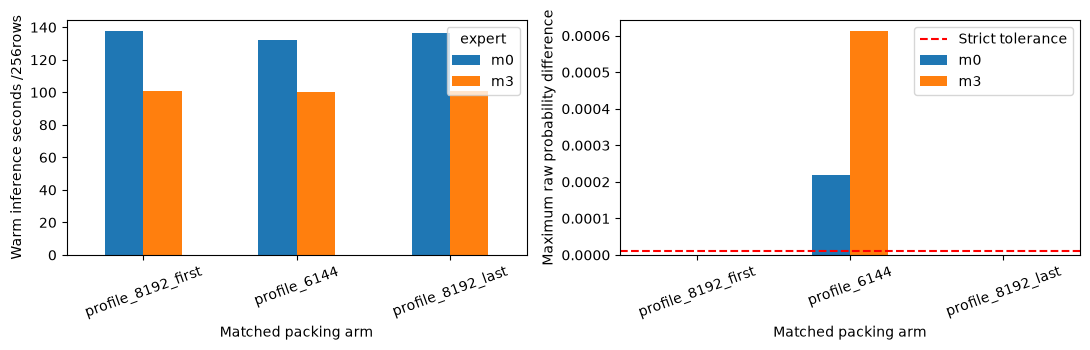

In [2]:
rows=[]
names=['profile_8192_first','profile_6144','profile_8192_last']
for role,summary in q['measured_roles'].items():
 for name in names:
  arm=summary['cohorts'][name]
  rows.append({'expert':role,'arm':name,'rows':arm['rows'],'seconds':arm['seconds'],
   'max_raw_difference':q['raw_control_differences'][role][name],
   'raw_control_passed':q['raw_control_differences'][role][name]<1e-5,
   'GPU0_peak_GB':arm['peak_allocated_bytes'][0]/1e9,'GPU1_peak_GB':arm['peak_allocated_bytes'][1]/1e9})
table=pd.DataFrame(rows);display(table)
fig,axes=plt.subplots(1,2,figsize=(11,3.5))
table.pivot(index='arm',columns='expert',values='seconds').reindex(names).plot.bar(ax=axes[0],rot=20)
axes[0].set_ylabel('Warm inference seconds /256rows');axes[0].set_xlabel('Matched packing arm')
table.pivot(index='arm',columns='expert',values='max_raw_difference').reindex(names).plot.bar(ax=axes[1],rot=20)
axes[1].axhline(1e-5,color='red',linestyle='--',label='Strict tolerance')
axes[1].set_ylabel('Maximum raw probability difference');axes[1].set_xlabel('Matched packing arm');axes[1].legend()
fig.tight_layout();plt.show()

H58tests one fixed recipe, only after E16passes. The existing label-free
Jensen–Shannon-disagreement-per-work route permits at most10%of estimated token
work and20%of rows. On that route the candidate is:

    .5 Gemma_original + .25 aligned_Llama_swapped + .25 Llama_original

Other rows retain the original equal two-expert ensemble. Temperature remains1.
Checkpoint, context, weights, route and class alignment are fixed in advance.
Cached original-vote results overlap checkpoint training: they are descriptive,
not independent CV or a competition-score estimate. A gain>0.0005on the fixed
uniform512cohort is an information gate only. The actual three-pass worker still
needs numerical/source/CSV/device controls and a conservative25krow projection
below9hours, including20%margin, startup/warmup/other overhead and600sreserve.

In [3]:
for name in ['H58_cached_replay.json','llama_order_qualification.json','llama_order_followup_qualification.json']:
 path=PUB/name
 if path.exists():
  print(name);display(read(name))
 else:print(name+': not available; this stage is incomplete.')
states=[]
for role in ['packing_profile','llama_order','llama_order_followup']:
 path=PUB/'jobs'/role/'status.json'
 if path.exists():states.append({'role':role,**json.loads(path.read_text())})
display(pd.DataFrame(states))
path=PUB/'official_result.json'
if path.exists():
 result=read('official_result.json')
 display(pd.DataFrame([{k:result.get(k) for k in ['ref','status','public_score','private_score','date']}]))
else:print('No official v12result yet.')
for name in ['official_leaderboard.json','leaderboard_status.json']:
 path=PUB/name
 if path.exists():
  print(name);display(pd.DataFrame([read(name)]))
print('Rank<=19on a fresh complete official leaderboard is required for goal completion.')

H58_cached_replay.json


{'at': '2026-11-07T19:18:43.659464+00:00',
 'information_gate_passed': False,
 'information_gain_threshold': 0.0005,
 'independent_local_quality': False,
 'original_votes_seen_in_checkpoint_training': True,
 'rule': 'on route: .5 Gemma original + .25 aligned Llama swapped + .25 Llama original; off route: base',
 'temperature': 1,
 'work_fraction': 0.1,
 'row_fraction': 0.2,
 'quality_variants_tested': 1,
 'coverage': {'control': {'rows': 256,
   'selected_rows': 42,
   'route_replayed': True,
   'selected_work_fraction': 0.09949411201819536,
   'independent': False,
   'baseline_log_loss': 0.5994288921356201,
   'candidate_log_loss': 0.5994868488475421,
   'loss_reduction': -5.800137902584989e-05,
   'descriptive_paired_group95': [-0.0017050833371984326,
    0.0015970283072924507],
   'baseline_accuracy': 0.7734375,
   'candidate_accuracy': 0.7734375,
   'class_loss_reduction': {'winner_model_a': -0.0010936191706436415,
    'winner_model_b': 0.00047636265798829366,
    'winner_tie': 0.

llama_order_qualification.json: not available; this stage is incomplete.
llama_order_followup_qualification.json: not available; this stage is incomplete.


,role,status,kernel_version,observed_at
0,packing_profile,COMPLETE,arseniytrushin/llm-preference-span012-packing-...,2026-11-07T19:15:50.332305+00:00


No official v12result yet.
leaderboard_status.json


,observed_at,complete,team_id,rank,teams,score,rank19_score,rank20_score,leader_score,target_achieved,latest_team_submission_date
0,2026-11-07T19:01:14.851718+00:00,True,17244411,30,313,0.83053,0.82915,0.82915,0.82704,False,2026-11-07T12:22:35.176Z


Rank<=19on a fresh complete official leaderboard is required for goal completion.
